In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
aryansinghal10_alzheimers_multiclass_dataset_equal_and_augmented_path = kagglehub.dataset_download('aryansinghal10/alzheimers-multiclass-dataset-equal-and-augmented')

print('Data source import complete.')


Using Colab cache for faster access to the 'alzheimers-multiclass-dataset-equal-and-augmented' dataset.
Data source import complete.


The Alzheimer's Disease Multiclass Dataset contains approximately 44,000 MRI images categorized into four distinct classes based on the severity of Alzheimer's disease. This dataset is intended for use in machine learning model training and testing. All images are skull-stripped and clean of non-brain tissue.

**Dataset Structure**
The dataset is organized into the following four directories, each representing a different class of disease severity:
- `NonDemented`: Contains 12,800 MRI images of subjects with no signs of dementia.
- `VeryMildDemented`: Contains 11,200 MRI images of subjects with very mild symptoms of dementia.
- `MildDemented`: Contains 10,000 MRI images of subjects with mild dementia.
- `ModerateDemented`: Contains 10,000 MRI images of subjects with moderate dementia.

**Image Details**
- Total Number of Images: 44,000
- Image Format: MRI scans as .JPG files
- Image Usage: Suitable for training and testing machine learning models focused on classifying Alzheimer's disease stages.

**Disease Severity Classification**
The dataset follows a severity ranking system for Alzheimer's disease:
- NonDemented: No dementia.
- Very Mild Demented: Early signs of dementia, very mild symptoms.
- Mild Demented: Clear signs of dementia, but still mild.
- Moderate Demented: More pronounced symptoms of dementia, moderate severity.

Our Aim is to build a Neural Network Model to be able to predict the severity of Patient's Alzheimer's disease, given the medical image of the Patient's MRI Scan.

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import pandas as pd
import numpy as np
from multiprocessing import Pool, cpu_count
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras import layers, models
import tensorflow as tf
import matplotlib.cm as cm
import warnings

warnings.filterwarnings("ignore")

In [ ]:
import os

print(os.listdir("/kaggle/input"))

['alzheimers-multiclass-dataset-equal-and-augmented']


In [ ]:
import os

dataset_path = "/kaggle/input/alzheimers-multiclass-dataset-equal-and-augmented"

print(os.listdir(dataset_path))

['combined_images']


In [ ]:
import os

working_directory = "/kaggle/input/alzheimers-multiclass-dataset-equal-and-augmented/combined_images"

print(os.listdir(working_directory))

['ModerateDemented', 'NonDemented', 'VeryMildDemented', 'MildDemented']


## Taking a look at 5 random Images from each classes

Classes:
['ModerateDemented', 'NonDemented', 'VeryMildDemented', 'MildDemented']


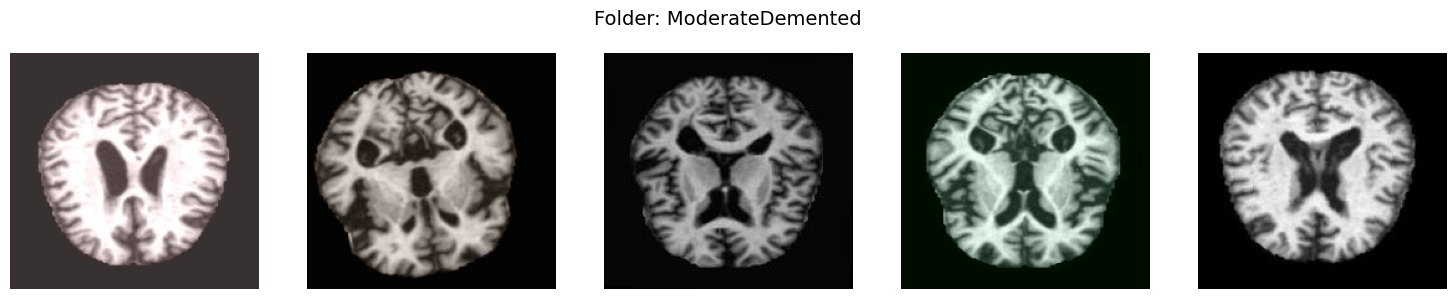

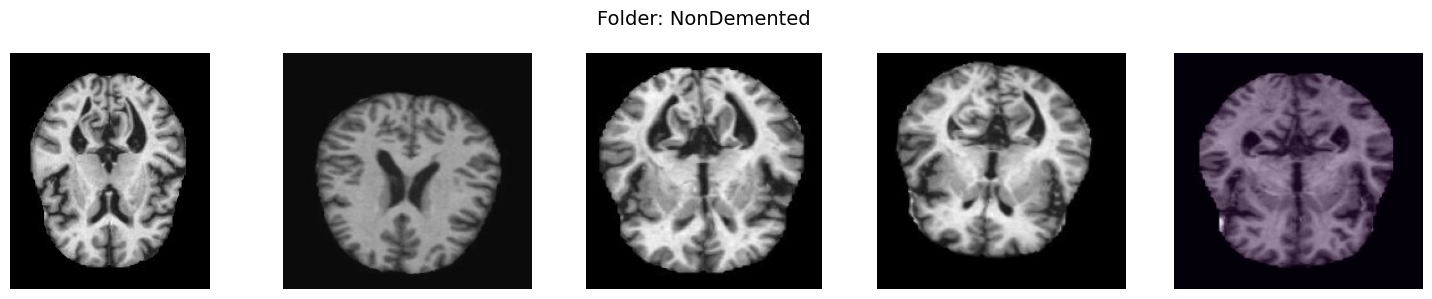

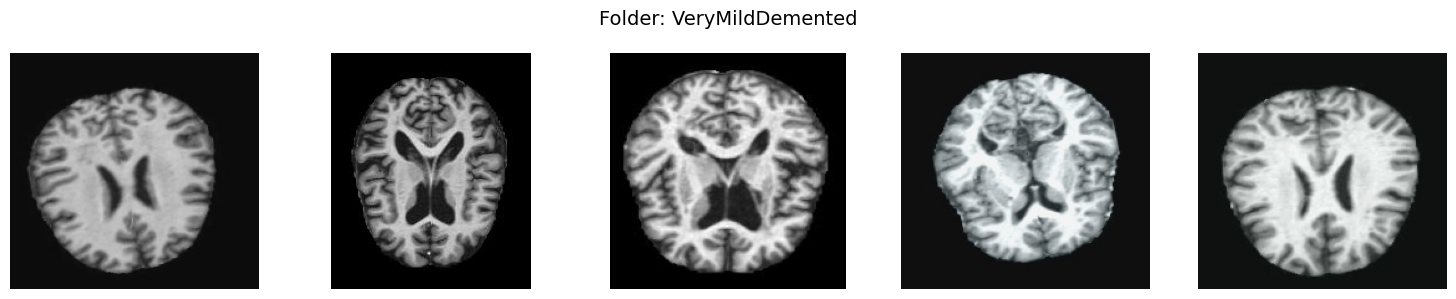

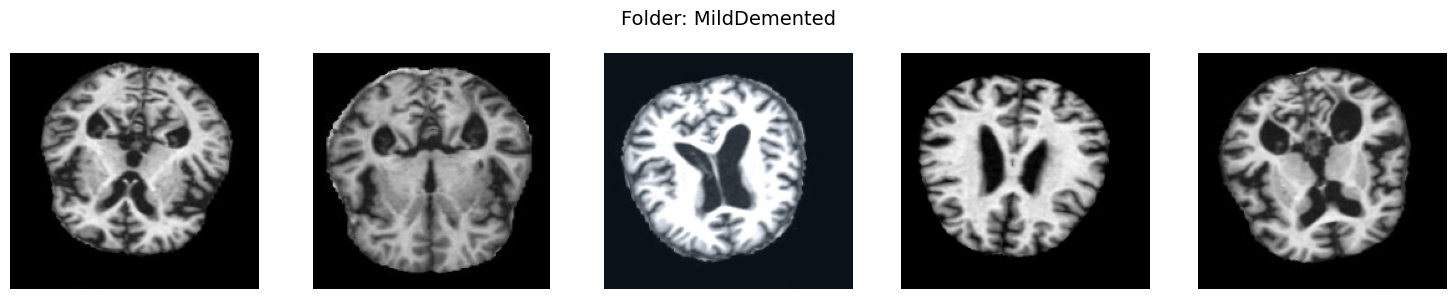

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Dataset path according to your Kaggle structure
working_directory = "/kaggle/input/alzheimers-multiclass-dataset-equal-and-augmented/combined_images"

# Get all class folders
img_folders = os.listdir(working_directory)

print("Classes:")
print(img_folders)

# Display 5 images from each class
for folder in img_folders:

    # Path of the class folder
    target_dir = os.path.join(working_directory, folder)

    # Make sure it is a folder
    if not os.path.isdir(target_dir):
        continue

    # Get only image files
    image_files = [
        file for file in os.listdir(target_dir)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Select first 5 images
    five_images = image_files[:5]

    # Create figure
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))

    # Display images
    for ax, path in zip(axes, five_images):

        img_path = os.path.join(target_dir, path)

        img = Image.open(img_path).convert("RGB")

        ax.imshow(img)
        ax.axis("off")

    # Class name
    plt.suptitle(f"Folder: {folder}", fontsize=14)

    plt.tight_layout()
    plt.show()

We see 5 images above from each of the different classes of Alzheimer present in our Dataset.

Let's store the information about the Folder structures and it's classes in a DataFrame.

## Storing Image Data in a DataFrame

In [ ]:
data = []
for folder_name in os.listdir(working_directory):
    folder_path = os.path.join(working_directory, folder_name)
    if os.path.isdir(folder_path):
        for img_name in os.listdir(folder_path):
            data.append({
                'FilePath': os.path.join(folder_path, img_name),
                'Label': folder_name
            })

df = pd.DataFrame(data)
print(f"Total images found and stored in the DataFrame: {len(df)}")
df.head()

Total images found and stored in the DataFrame: 44000


,FilePath,Label
0,/kaggle/input/alzheimers-multiclass-dataset-eq...,ModerateDemented
1,/kaggle/input/alzheimers-multiclass-dataset-eq...,ModerateDemented
2,/kaggle/input/alzheimers-multiclass-dataset-eq...,ModerateDemented
3,/kaggle/input/alzheimers-multiclass-dataset-eq...,ModerateDemented
4,/kaggle/input/alzheimers-multiclass-dataset-eq...,ModerateDemented


## Analyzing the Distribution of the classes

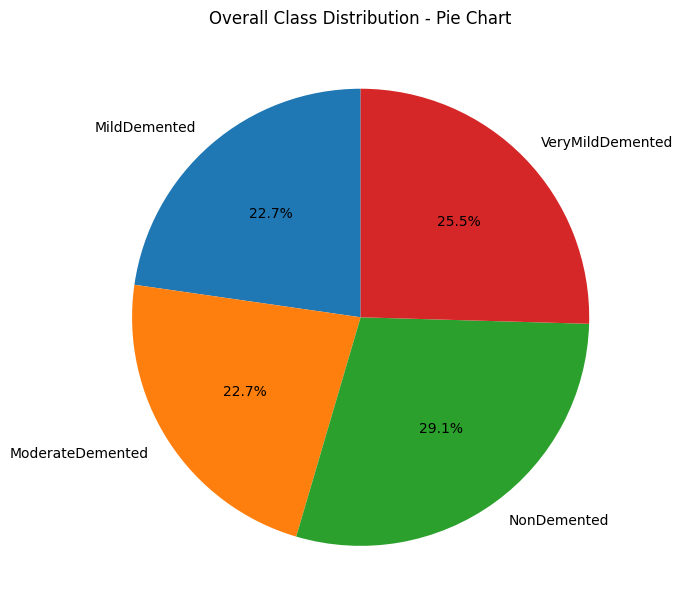

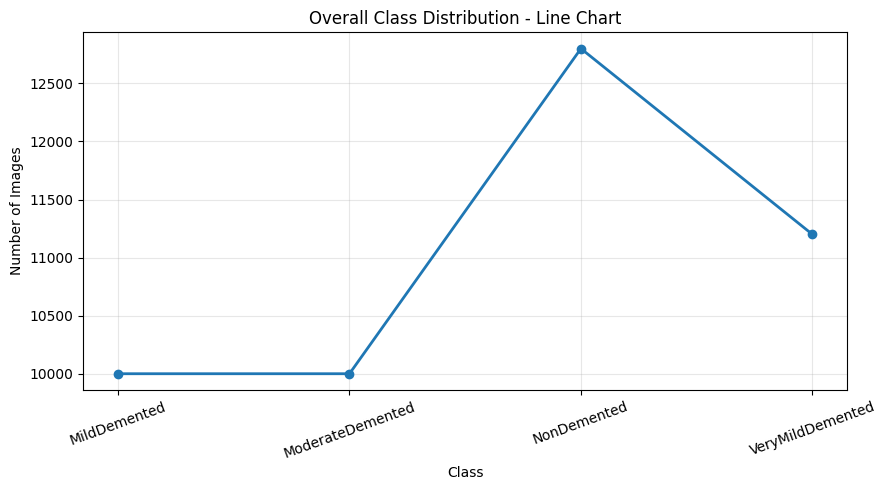

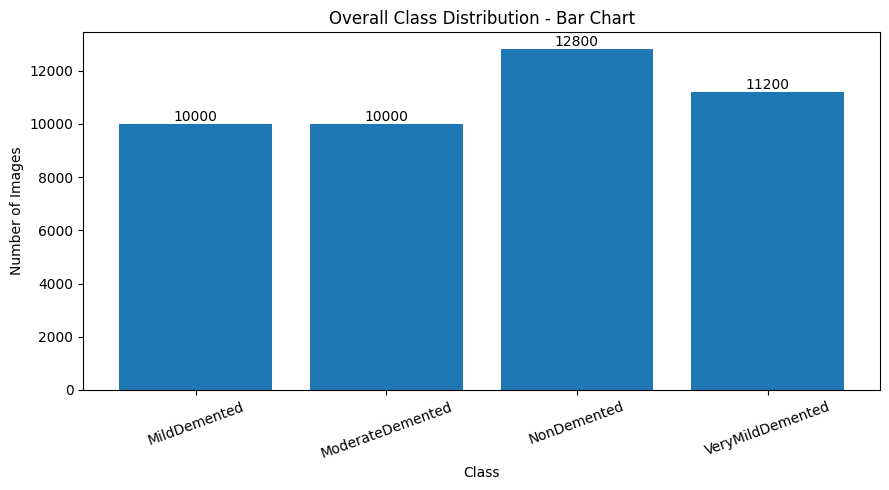

In [ ]:
# Overall Class Distribution - Pie, Line and Bar Charts

class_counts = df["Label"].value_counts().sort_index()

# 1. Pie Chart
plt.figure(figsize=(7, 7))
plt.pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Overall Class Distribution - Pie Chart")
plt.tight_layout()
plt.show()

# 2. Line Chart
plt.figure(figsize=(9, 5))
plt.plot(
    class_counts.index,
    class_counts.values,
    marker="o",
    linewidth=2
)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Overall Class Distribution - Line Chart")
plt.xticks(rotation=20)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Bar Chart
plt.figure(figsize=(9, 5))
bars = plt.bar(class_counts.index, class_counts.values)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Overall Class Distribution - Bar Chart")
plt.xticks(rotation=20)
plt.bar_label(bars)
plt.tight_layout()
plt.show()


We have more NonDemented and VeryMildDemented than ModerateDemented and MildDemented.

We would be careful when splitting the dataset to ensure that there is a balance between our Training, Validation and Testing Set.

Let's explore the Physical Properties of Images, most especially the Image Size and the Color Channels of the Images.

## Extract Image Size and Color Channels for all images

In [ ]:
def read_image_metadata(path):
    try:
        with Image.open(path) as img:
            return [img.size[0], img.size[1], img.size, img.mode, len(img.getbands())]
    except:
        return [None, None, None, None, None]

def collect_image_metadata(df):
    num_cores = cpu_count()
    print(f"Launching {num_cores} parallel workers...")

    with Pool(num_cores) as pool:
        results = list(tqdm(pool.imap(read_image_metadata, df['FilePath']),
                           total=len(df),
                           desc="Multiprocessing Extraction"))

    meta_columns = ['Width', 'Height', 'Size', 'Mode', 'Channels']
    meta_df = pd.DataFrame(results, columns=meta_columns)

    return pd.concat([df.reset_index(drop=True), meta_df], axis=1)

df = collect_image_metadata(df)

Launching 2 parallel workers...


Multiprocessing Extraction: 100%|██████████| 44000/44000 [00:34<00:00, 1283.95it/s]


In [ ]:
print(f"Number of Images that failed to process: {df['Width'].isnull().sum()} images")

print("\nDistribution of Image Sizes")
df['Size'].value_counts().reset_index()

Number of Images that failed to process: 0 images

Distribution of Image Sizes


,Size,count
0,"(200, 190)",31107
1,"(180, 180)",6447
2,"(176, 208)",6446


The images don't have a single size, we have more images of size `120 by 120`, compared to `180 by 180` and `176 by 208`.
We will have to unify this sizes and set them to a preferred size for our model.

We can also explore more about the sizes to see if if they are tied to their classes.


In [ ]:
# Bias Audit of Size and their Labels
df.groupby(['Size', 'Label']).size().unstack()

Label,MildDemented,ModerateDemented,NonDemented,VeryMildDemented
Size,,,,
"(176, 208)",911,95,3200,2240
"(180, 180)",913,94,3200,2240
"(200, 190)",8176,9811,6400,6720


The result above shows that the dataset is robust against metadata shortcuts (Labels cannot be easily inferred based on Image size).

We can safely assume that because no single size is exclusive to a single label, the model cannot "cheat" by simply looking at the image dimensions to guess the disease stage.

It is also clear that majority of the images are in the `200 by 190` scale.

Time to check the distribution of the mode/color channel of the images:

In [ ]:
print("\nDistribution of Image Modes/Channels")
df['Mode'].value_counts().reset_index()


Distribution of Image Modes/Channels


,Mode,count
0,RGB,33984
1,L,10016


10k of the images are greyscale images, we will have to force them into RGB Modes.

This is because our proposed model - the **EfficientNet** expect 3 channels or RGB Images. If our data loader hits a 1-channel image while expecting 3, it would throw a dimension mismatch error.

We will carry out the following preprocessing step:

- Image resizing with aspect ratio preservation and padding: Each image will be scaled so that its longest side is 224 pixels, after which zero-padding will be applied to the shorter side to obtain a square image of size 224 × 224.

The choice of 224 × 224 is motivated by transfer-learning conventions and aligns with the native input resolution of EfficientNet-B0.

- Split the data into Training, Validation and Testing Test:
We will distribute in the following proportions:
    - Train Set (80%): $35,200$ images.
    - Validation Set (10%): $4,400$ images.
    - Test Set (10%): $4,400$ images.

## Splitting the Dataset

In [ ]:
train_val_df, test_df = train_test_split(
    df,
    test_size=0.10,
    stratify=df['Label'],
    random_state=42
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.1111,
    stratify=train_val_df['Label'],
    random_state=42
)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 35200 | Val: 4400 | Test: 4400


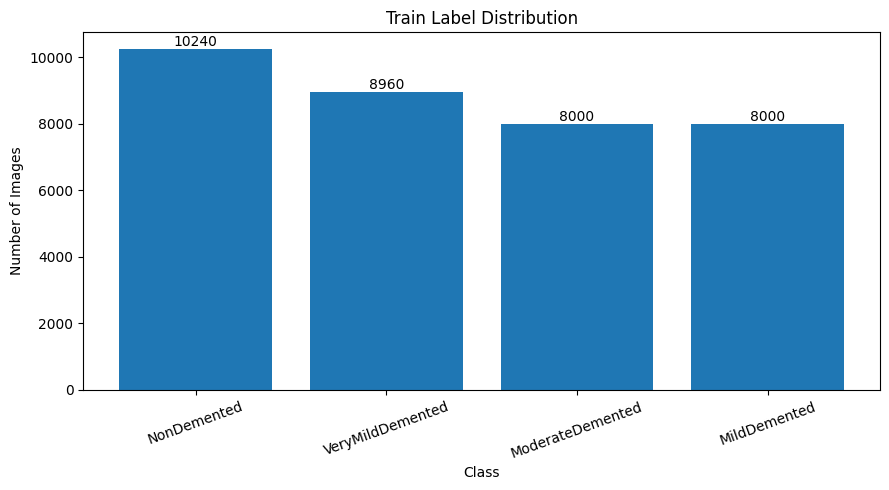


TRAIN DISTRIBUTION
Label
NonDemented         29.090909
VeryMildDemented    25.454545
ModerateDemented    22.727273
MildDemented        22.727273
Name: proportion, dtype: float64


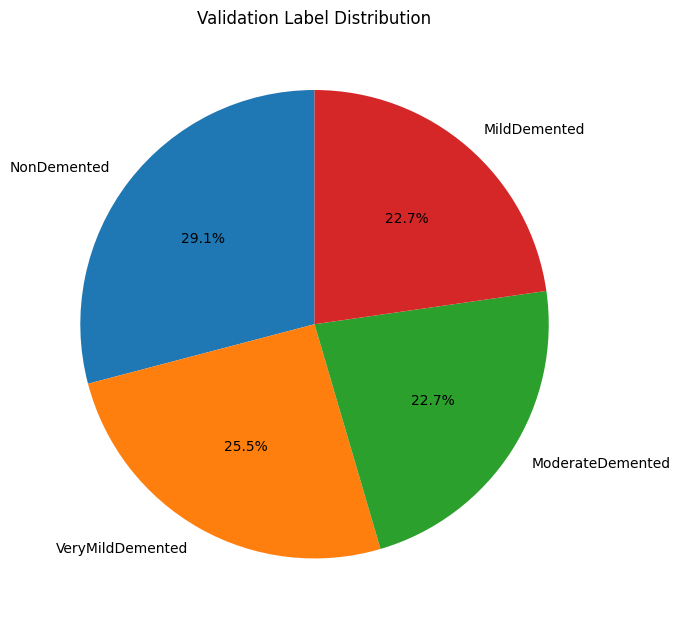


VALIDATION DISTRIBUTION
Label
NonDemented         29.090909
VeryMildDemented    25.454545
ModerateDemented    22.727273
MildDemented        22.727273
Name: proportion, dtype: float64


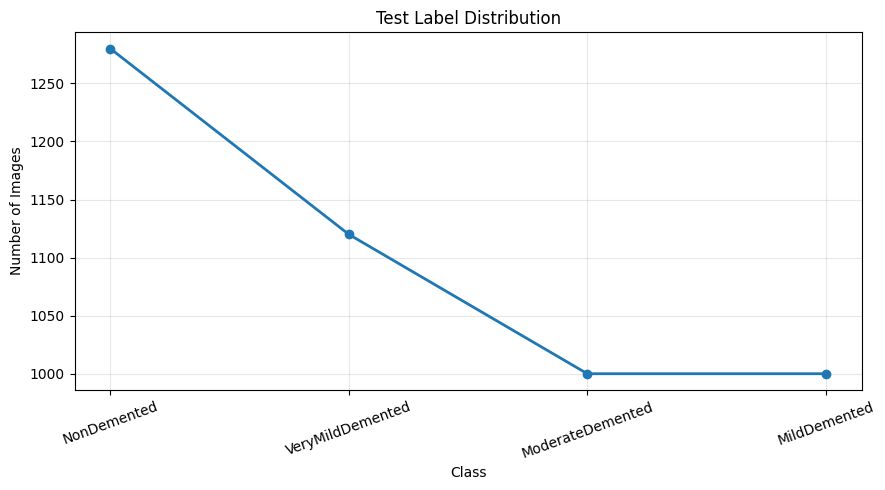


TEST DISTRIBUTION
Label
NonDemented         29.090909
VeryMildDemented    25.454545
ModerateDemented    22.727273
MildDemented        22.727273
Name: proportion, dtype: float64


In [ ]:
# Separate label distribution charts
# Train = Bar Chart | Validation = Pie Chart | Test = Line Chart

classes = [
    "NonDemented",
    "VeryMildDemented",
    "ModerateDemented",
    "MildDemented"
]

# =========================
# TRAIN DISTRIBUTION - BAR CHART
# =========================
train_counts = train_df["Label"].value_counts().reindex(classes, fill_value=0)

plt.figure(figsize=(9, 5))
bars = plt.bar(train_counts.index, train_counts.values)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Train Label Distribution")
plt.xticks(rotation=20)
plt.bar_label(bars)
plt.tight_layout()
plt.show()

print("\nTRAIN DISTRIBUTION")
print((train_counts / train_counts.sum() * 100).rename("proportion"))


# =========================
# VALIDATION DISTRIBUTION - PIE CHART
# =========================
val_counts = val_df["Label"].value_counts().reindex(classes, fill_value=0)

plt.figure(figsize=(7, 7))
plt.pie(
    val_counts.values,
    labels=val_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Validation Label Distribution")
plt.tight_layout()
plt.show()

print("\nVALIDATION DISTRIBUTION")
print((val_counts / val_counts.sum() * 100).rename("proportion"))


# =========================
# TEST DISTRIBUTION - LINE CHART
# =========================
test_counts = test_df["Label"].value_counts().reindex(classes, fill_value=0)

plt.figure(figsize=(9, 5))
plt.plot(
    test_counts.index,
    test_counts.values,
    marker="o",
    linewidth=2
)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Test Label Distribution")
plt.xticks(rotation=20)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTEST DISTRIBUTION")
print((test_counts / test_counts.sum() * 100).rename("proportion"))


We can observe that the classes are well distributed accross all splits.

We will use the splits for the following:
- Training Set: This will be used by the model to learn the MRI patterns.
- Validation Set: This will be used during training to evaluate the model.
- Test Set: This stays completely untouched and unused until the very end to prove our model works on unseen data, to evaluate it's finalgeneralization power.

Time to encode the Label names...

## Preprocessing the different Splits

In [ ]:
label_map = {
    'NonDemented': 0,
    'VeryMildDemented': 1,
    'MildDemented': 2,
    'ModerateDemented': 3
}

train_df['LabelNum'] = train_df['Label'].map(label_map)
val_df['LabelNum'] = val_df['Label'].map(label_map)
test_df['LabelNum'] = test_df['Label'].map(label_map)

We will load the dataset into a stream for our model.

In [ ]:
BATCH_SIZE = 32
# IMG_SIZE = (224, 224)

def load_and_preprocess(path, label):
    # Read Image
    img = tf.io.read_file(path)
    # Force any image mode to RGB Mode/Channel
    img = tf.image.decode_jpeg(img, channels=3)
    # Resize and Pad
    img = tf.image.resize_with_pad(img, 224, 224)
    img = tf.cast(img, tf.float32)
    return img, label


def create_dataset(dataframe, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((dataframe['FilePath'].values, dataframe['LabelNum'].values))
    # Using all CPU cores
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=1000)
    # Batch and prefetch to keep the GPU busy
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# Creating the stream for all Splits
train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

## Building the Model

In [ ]:
def build_model(num_classes=4):
    inputs = tf.keras.Input(shape=(224, 224, 3))

    base = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
    )
    base.trainable = False

    x = tf.keras.applications.efficientnet.preprocess_input(inputs)
    x = base(x, training=False)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.4)(x)
    x = tf.keras.layers.Dense(256, activation="relu")(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

    return tf.keras.Model(inputs, outputs)

# Initializing our Model
model = build_model(num_classes=4)

# Compiling our model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,655 (16.72 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

**⚠️NOTE**:

You should only **Run** this cell below if there are more than 1 GPU in the current runtime.
This will allow the efficient utilisation of ALL AVAILABLE GPUs and will Speed Up the Training Process significantly.

In [ ]:
strategy = tf.distribute.MirroredStrategy()
print(f"Number of devices: {strategy.num_replicas_in_sync}")

with strategy.scope():
    model = build_model(num_classes=4)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

model.summary()

Number of devices: 1


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,655 (16.72 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

## Training the Model

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    # Lower the learning rate if we get 'stuck' on a plateau
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.2, patience=3),
    # Save the best version of our model automatically
    tf.keras.callbacks.ModelCheckpoint('alzheimer_model.keras', save_best_only=True)
]

# Launching the training with 40 Epochs
EPOCHS = 40

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/40
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 112s 91ms/step - accuracy: 0.6126 - loss: 0.9045 - val_accuracy: 0.7248 - val_loss: 0.6100 - learning_rate: 0.0010
Epoch 2/40
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 97s 88ms/step - accuracy: 0.6855 - loss: 0.7084 - val_accuracy: 0.7582 - val_loss: 0.5250 - learning_rate: 0.0010
Epoch 3/40
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 97s 87ms/step - accuracy: 0.7190 - loss: 0.6405 - val_accuracy: 0.8082 - val_loss: 0.4536 - learning_rate: 0.0010
Epoch 4/40
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 97s 87ms/step - accuracy: 0.7461 - loss: 0.5823 - val_accuracy: 0.8336 - val_loss: 0.3989 - learning_rate: 0.0010
Epoch 5/40
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 96s 87ms/step - accuracy: 0.7672 - loss: 0.5430 - val_accuracy: 0.8614 - val_loss: 0.3555 - learning_rate: 0.0010
Epoch 6/40
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 144s 88ms/step - accuracy: 0.7847 - loss: 0.5078 - val_accuracy: 0.8491 - val_loss: 0.3490 - learning_rate: 0.0010
Epoch 7/40
1100/1100 ━━━━━━━━━━━━━━━━━━━━ 98s 88ms/step - accu

### <u>Observations</u>
A clear learning trend was evident from the first epoch, with the model achieving a **validation accuracy of approximately 75%** in it's first epoch. This demonstrates that the pretrained backbone provided meaningful feature representations prior to extensive task-specific training.

- Training time was approximately `40` seconds per epoch, for a total duration of `~26` minutes

- Epoch 39 is the best model with the lowest `validation_loss`  and highest `validation accuracy`; The epoch had been automatically saved to our environment.

## Evaluate the Model on Testing Split/Set

138/138 ━━━━━━━━━━━━━━━━━━━━ 22s 116ms/step


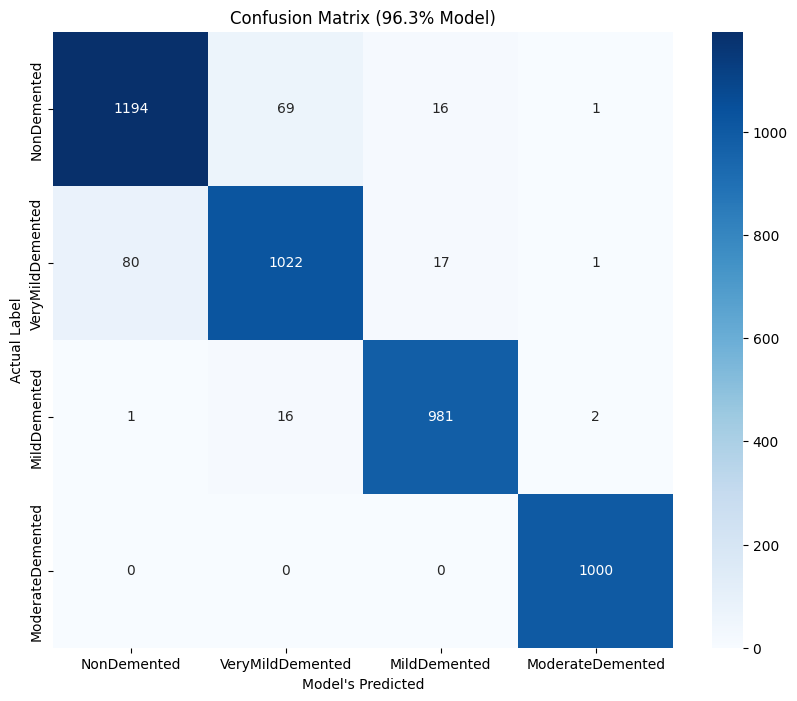

                  precision    recall  f1-score   support

     NonDemented       0.94      0.93      0.93      1280
VeryMildDemented       0.92      0.91      0.92      1120
    MildDemented       0.97      0.98      0.97      1000
ModerateDemented       1.00      1.00      1.00      1000

        accuracy                           0.95      4400
       macro avg       0.96      0.96      0.96      4400
    weighted avg       0.95      0.95      0.95      4400



In [ ]:
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = np.concatenate([y for x, y in test_ds], axis=0)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_map.keys(),
            yticklabels=label_map.keys())
plt.xlabel("Model's Predicted")
plt.ylabel('Actual Label')
plt.title('Confusion Matrix (96.3% Model)')
plt.show()

print(classification_report(y_true, y_pred, target_names=label_map.keys()))

In [ ]:
from google.colab import drive
import os

# Connect Google Drive
drive.mount('/content/drive')

# Create the alz folder if it doesn't exist
os.makedirs('/content/drive/MyDrive/alz', exist_ok=True)

# Save the trained model
model.save('/content/drive/MyDrive/alz/alzheimer_model.keras')

print("✅ Model saved successfully!")

Mounted at /content/drive
✅ Model saved successfully!


In [ ]:
from google.colab import files

files.download('/content/drive/MyDrive/alz/alzheimer_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Our model achieved an oustanding score for the `ModerateDemented` Cases:
- **Precision:** 1.00 (100%)
- **Recall:** 1.00 (100%)
  
Our model NEVER missed a severe case. This is the most critical metric because missing a severe patient is dangerous.

And in the case of Non, Mild and Very Mild
- The model confused **65** `Very Mild` patients as `Non Demented` (False Negatives).
- The model confused **4** `Mild` patients as `Non Demented` (Fale Negatives).
- The model confused **45** `Non Demented` patients as `Very Mild` (False Positives).
- The model confused **8** `Mild` patients as `Very Mild` (False Positives).
- The model confused **12** `Non Demented` patients as `Mild` (False Positives).
- The model confused **17** `Very Mild` patients as `Mild` (False Negatives).
- The model confused **1** `Very Mild` patients as `Moderate` (False Postive).
- The model confused **1** `Mild` patients as `Moderate` (False Postive).

But it rarely confused `Non Demented` with `Moderate` and vice-versa. This means the model isn't guessing when it comes to Moderate Cases.


We were able to achieve an accuracy of `96.3%` with `100%` recall on the most severe class/case(`ModerateDemented`).

| Metric | Our Result |
| --- | --- |
| **Accuracy** | **96.6%** |
| **Recall** | **100%** |

---
---
